* 2.dünya savaşı sırasında bomba atılan yerlerin datası ile çalışacağız.
* Uçağın havalandığı enlem(Latitude)(36,42) , boylam (Longitude) (26,45)
* 
* 

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.plotly as py 
from plotly.offline import init_notebook_mode, iplot # plotly offline mode
init_notebook_mode(connected=True) 
import plotly.graph_objs as go # plotly graphical object

#import os
#print(os.listdir("../input"))

import warnings  
warnings.filterwarnings("ignore")
plt.style.use('ggplot')

## Load the Data
* As I mentioned at introduction, we use multiple data sources.
    * Aerial Bombing Operations in WW2
        * Shortly, this data includes bombing operations. For example, USA who use ponte olivo airfield bomb Germany (Berlin) with A36 air craft in 1945.
    * Wether Conditions in WW2
        * Shortly, weather conditions during ww2. For example, according to george town weather station, average temperature is 23.88 in 1/7/1942. 
        * This data set has 2 subset in it. First one includes weather station locations like country, latitude and longitude.
        * Second one includes measured min, max and mean temperatures from weather stations.

In [5]:
# bombing data
aerial = pd.read_csv("Plotly1/operations.csv")
# first weather data that includes locations like country, latitude and longitude.
weather_station_location = pd.read_csv("Plotly1/Weather Station Locations.csv")
# Second weather data that includes measured min, max and mean temperatures
weather = pd.read_csv("Plotly1/Summary of Weather.csv")

In [7]:
aerial.head()

,Mission ID,Mission Date,Theater of Operations,Country,Air Force,Unit ID,Aircraft Series,Callsign,Mission Type,Takeoff Base,...,Incendiary Devices Weight (Tons),Fragmentation Devices,Fragmentation Devices Type,Fragmentation Devices Weight (Pounds),Fragmentation Devices Weight (Tons),Total Weight (Pounds),Total Weight (Tons),Time Over Target,Bomb Damage Assessment,Source ID
0,1,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN
1,2,8/15/1943,PTO,USA,5 AF,400 BS,B24,NaN,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN,9366.0
2,3,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
3,4,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,7.5,NaN,NaN,NaN
4,5,8/15/1943,PTO,USA,5 AF,321 BS,B24,NaN,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,NaN,22585.0



## Data Description
I only explain data features that we will use in this kernel.
* **Aerial bombing Data description:**
    * Mission Date: Date of mission
    * Theater of Operations: Region in which active military operations are in progress; "the army was in the field awaiting action"; Example: "he served in the Vietnam theater for three years"
    * Country: Country that makes mission or operation like USA
    * Air Force: Name or id of air force unity like 5AF
    * Aircraft Series: Model or type of aircraft like B24
    * Callsign: Before bomb attack, message, code, announcement, or tune that is broadcast by radio.
    * Takeoff Base: Takeoff airport name like Ponte Olivo Airfield 
    * Takeoff Location: takeoff region Sicily
    * Takeoff Latitude: Latitude of takeoff region
    * Takeoff Longitude: Longitude of takeoff region
    * Target Country: Target country like Germany
    * Target City: Target city like Berlin
    * Target Type: Type of target like city area
    * Target Industry: Target industy like town or urban
    * Target Priority: Target priority like 1 (most)
    * Target Latitude: Latitude of target 
    * Target Longitude: Longitude of target
* **Weather Condition data description:**
    * Weather station location:
        * WBAN: Weather station number
        * NAME: weather station name
        * STATE/COUNTRY ID: acronym of countries
        * Latitude: Latitude of weather station
        * Longitude: Longitude of weather station
    * Weather:
        * STA: eather station number (WBAN)
        * Date: Date of temperature  measurement 
        * MeanTemp: Mean temperature


## Data Cleaning
* Aerial  Bombing data includes a lot of NaN value. Instead of usign them, I drop some NaN values. It does not only remove the uncertainty but it also easa visualization process.
    * Drop countries that are NaN
    * Drop if target longitude is NaN
    * Drop if takeoff longitude is NaN
    * Drop unused features
* Weather Condition data does not need any cleaning. According to exploratory data analysis and visualization, we will choose certain location to examine deeper. However, lets put our data variables what we use only. 

## Data Visualization
* Lets start with basics of visualization that is understanding data.
    * How many country which attacks
    * Top target countries
    * Top 10 aircraft series
    * Takeoff base locations (Attacjk countries)
    * Bombing paths
    * Theater of Operations
    * Weather station locations

In [19]:
aerial.head()

,Mission ID,Mission Date,Theater of Operations,Country,Air Force,Unit ID,Aircraft Series,Callsign,Mission Type,Takeoff Base,...,Incendiary Devices Weight (Tons),Fragmentation Devices,Fragmentation Devices Type,Fragmentation Devices Weight (Pounds),Fragmentation Devices Weight (Tons),Total Weight (Pounds),Total Weight (Tons),Time Over Target,Bomb Damage Assessment,Source ID
0,1,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN
1,2,8/15/1943,PTO,USA,5 AF,400 BS,B24,NaN,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN,9366.0
2,3,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
3,4,8/15/1943,MTO,USA,12 AF,27 FBG/86 FBG,A36,NaN,NaN,PONTE OLIVO AIRFIELD,...,NaN,NaN,NaN,NaN,NaN,NaN,7.5,NaN,NaN,NaN
4,5,8/15/1943,PTO,USA,5 AF,321 BS,B24,NaN,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,NaN,22585.0


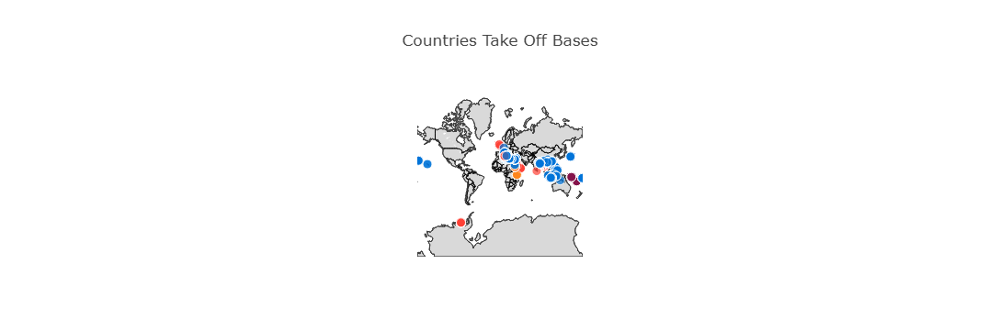

In [21]:
import plotly.graph_objs as go
from plotly.offline import iplot

# Varsayılan renk ata
# saldırı yapan ülkeler renkler atadık
aerial["color"] = "rgb(200,200,200)"
aerial.loc[aerial.Country == "USA", "color"] = "rgb(0,116,217)"
aerial.loc[aerial.Country == "GREAT BRITAIN", "color"] = "rgb(255,65,54)"
aerial.loc[aerial.Country == "NEW ZEALAND", "color"] = "rgb(133,20,75)"
aerial.loc[aerial.Country == "SOUTH AFRICA", "color"] = "rgb(255,133,27)"

data = [dict(
    type='scattergeo',
    lon=aerial['Takeoff Longitude'],
    lat=aerial['Takeoff Latitude'],
    hoverinfo='text', #corser -üstüne geldiğimizde çıkan
    text="Country: " + aerial.Country + 
         "<br>Takeoff Location: " + aerial["Takeoff Location"] +
         "<br>Takeoff Base: " + aerial['Takeoff Base'],
    # saldırı yapan ülke - ülkenin konumu bölgesi - kalktığı havaalanı
    mode='markers',
    marker=dict(
        sizemode='area',
        sizeref=1,
        size=10,
        line=dict(width=1, color="white"), # topçuğun etrafındaki line rengi
        color=aerial["color"], # markerlarn colorunu şuna göre define ettik
        opacity=0.7),
)]

layout = dict(
    title='Countries Take Off Bases',
    hovermode='closest',
    geo=dict(
        showframe=False,  # frame gösterme
        showland=True,    # arazi göster
        showcoastlines=True, # kıyı  kenar göster
        showcountries=True, # ülke göste
        countrywidth=1,
        projection=dict(type='mercator'),  # ✅ düzeltme burada
        landcolor='rgb(217, 217, 217)', # beyaza yakın gri 
        subunitwidth=1,
        showlakes=True, # gölleri göster
        lakecolor='rgb(255, 255, 255)', # göllerin rengi beyaz olsun
        countrycolor="rgb(5, 5, 5)")
)

fig = go.Figure(data=data, layout=layout)
iplot(fig)


In [23]:
# 2.dünya savaşında amerika ve ingiltere buralardan saldırılar düzenlemiş yani üs bölgeleri
# daha sonra nerelere saldırdığını da gözlemleyeceğiz.

In [25]:
aerial['Takeoff Longitude']


0         14.321464
1               NaN
2         14.321464
3         14.321464
4               NaN
            ...    
178276          NaN
178277          NaN
178278          NaN
178279          NaN
178280          NaN
Name: Takeoff Longitude, Length: 178281, dtype: float64

In [27]:
# ilk olarak uçakların nerden kalktığını bulalım yukardan

In [ ]:
# Bombing paths


#Uçakların kalktığı üsler
# trace1
airports = [ dict(
        type = 'scattergeo',
        lon = aerial['Takeoff Longitude'],
        lat = aerial['Takeoff Latitude'],
        hoverinfo = 'text',
        text = "Country: " + aerial.Country + " Takeoff Location: "+aerial["Takeoff Location"]+" Takeoff Base: " + aerial['Takeoff Base'],
        mode = 'markers',
        marker = dict( 
            size=5, 
            color = aerial["color"],
            line = dict(
                width=1,
                color = "white"
            )
        ))]



# Burada da vurulan bomba atılan varış noktaları
# trace2
targets = [ dict(
        type = 'scattergeo',
        lon = aerial['Target Longitude'],
        lat = aerial['Target Latitude'],
        hoverinfo = 'text',
        text = "Target Country: "+aerial["Target Country"]+" Target City: "+aerial["Target City"],
        mode = 'markers',
        marker = dict( 
            size=1, 
            color = "red", # saldırı yapılan ülkelerin hepsi kırmızı
            line = dict(
                width=0.5,
                color = "red"
            )
        ))]

# iki tane noktayı çizgi ile birleştirebiliriz.
# trace3
flight_paths = []
for i in range( len( aerial['Target Longitude'] ) ):
    flight_paths.append(
        dict(
            type = 'scattergeo',
            #target long kadar for döngüsü,kalkış yaptığı boylam, İniş yaptığı boylam
            # 8,9 değerleri kullanılan dataframedeki column numaraları yani enlem ve boylamın dataframe de bulundukları columnlar
            lon = [ aerial.iloc[i,9], aerial.iloc[i,16] ],
            lat = [ aerial.iloc[i,8], aerial.iloc[i,15] ],
            mode = 'lines',
            line = dict(
                width = 0.7,
                color = 'black',
            ),
            opacity = 0.6,
        )
    )
    
layout = dict(
    title = 'Bombing Paths from Attacker Country to Target ',
    hovermode='closest',
    geo = dict(showframe=False, showland=True, showcoastlines=True, showcountries=True,
               countrywidth=1, projection=dict(type='Mercator'),
              landcolor = 'rgb(217, 217, 217)',
              subunitwidth=1,
              showlakes = True,
              lakecolor = 'rgb(255, 255, 255)',
              countrycolor="rgb(5, 5, 5)")
)
    
fig = dict( data=flight_paths + airports+targets, layout=layout )
iplot( fig )